In [1]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: D:\Fraud-Detection\.venv\Scripts\python.exe
Python version: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
DATA_PATH = "../data/raw/"

print(os.listdir(DATA_PATH))

['sample_submission.csv', 'test_identity.csv', 'test_transaction.csv', 'train_identity.csv', 'train_transaction.csv']


In [4]:
train_transaction = pd.read_csv(
    DATA_PATH + "train_transaction.csv"
)

train_identity = pd.read_csv(
    DATA_PATH + "train_identity.csv"
)

print("Transaction shape:", train_transaction.shape)
print("Identity shape:", train_identity.shape)


Transaction shape: (590540, 394)
Identity shape: (144233, 41)


In [5]:
train = train_transaction.merge(
    train_identity,
    on="TransactionID",
    how="left"
)

print("Merged dataset shape:", train.shape)

Merged dataset shape: (590540, 434)


In [6]:
print("First 5 rows:")
display(train.head())

print("\nDataset information:")
print("Total rows:", train.shape[0])
print("Total columns:", train.shape[1])

print("\nTarget column:")
print(train["isFraud"].value_counts())

First 5 rows:


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M



Dataset information:
Total rows: 590540
Total columns: 434

Target column:
isFraud
0    569877
1     20663
Name: count, dtype: int64


In [7]:
fraud_counts = train["isFraud"].value_counts()

fraud_percentage = train["isFraud"].value_counts(normalize=True) * 100

print("Class Counts:")
print(fraud_counts)

print("\nClass Percentages:")
print(fraud_percentage)

Class Counts:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Class Percentages:
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64


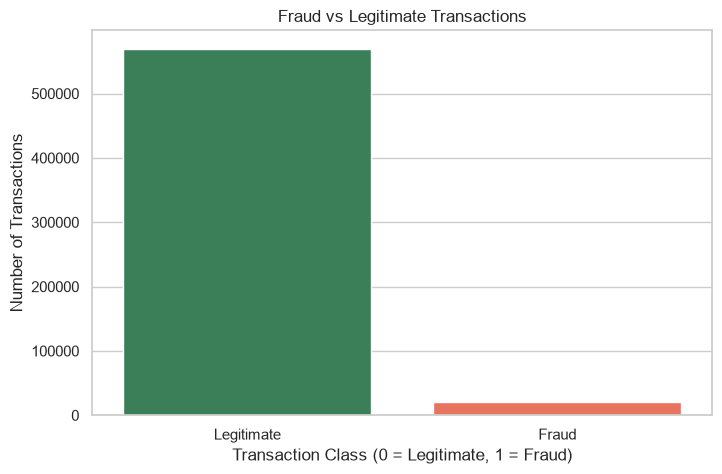

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="isFraud",
    hue="isFraud",
    palette=["seagreen", "tomato"],
    legend=False
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()

In [9]:
missing_values = train.isnull().sum()

missing_percentage = (
    missing_values / len(train)
) * 100

missing_df = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": missing_percentage
})

missing_df = missing_df.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_df.head(20))

,Missing_Count,Missing_Percentage
id_24,585793,99.196159
id_25,585408,99.130965
id_07,585385,99.127070
id_08,585385,99.127070
id_21,585381,99.126393
id_26,585377,99.125715
id_27,585371,99.124699
id_23,585371,99.124699
id_22,585371,99.124699
dist2,552913,93.628374


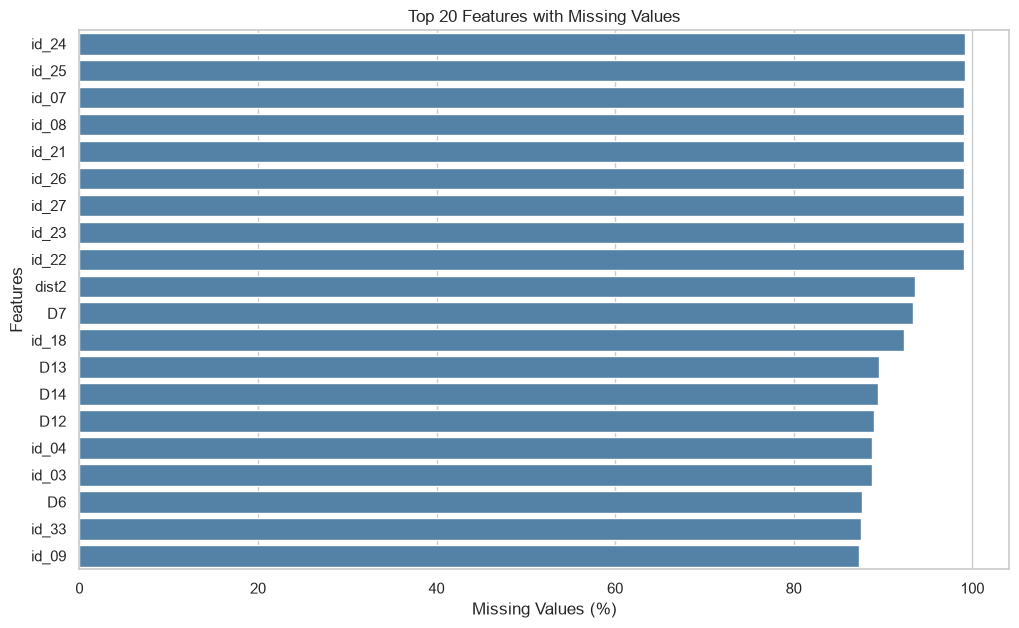

In [10]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=missing_df.head(20),
    x="Missing_Percentage",
    y=missing_df.head(20).index,
    color="steelblue"
)

plt.title("Top 20 Features with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.show()

In [11]:
missing_pct = train.isnull().mean() * 100

print("Columns with more than 90% missing:",
      (missing_pct > 90).sum())

print("Columns with 50–90% missing:",
      ((missing_pct >= 50) & (missing_pct <= 90)).sum())

print("Columns with 10–50% missing:",
      ((missing_pct >= 10) & (missing_pct < 50)).sum())

print("Columns with less than 10% missing:",
      (missing_pct < 10).sum())

Columns with more than 90% missing: 12
Columns with 50–90% missing: 202
Columns with 10–50% missing: 108
Columns with less than 10% missing: 112


In [12]:
print("Minimum TransactionDT:", train["TransactionDT"].min())
print("Maximum TransactionDT:", train["TransactionDT"].max())

print("\nFirst 10 TransactionDT values:")
print(train["TransactionDT"].head(10))

Minimum TransactionDT: 86400
Maximum TransactionDT: 15811131

First 10 TransactionDT values:
0    86400
1    86401
2    86469
3    86499
4    86506
5    86510
6    86522
7    86529
8    86535
9    86536
Name: TransactionDT, dtype: int64


In [13]:
train_sorted = train.sort_values(
    by="TransactionDT"
).reset_index(drop=True)

print("Chronological sorting completed!")

print("\nFirst transaction time:",
      train_sorted["TransactionDT"].iloc[0])

print("Last transaction time:",
      train_sorted["TransactionDT"].iloc[-1])

Chronological sorting completed!

First transaction time: 86400
Last transaction time: 15811131


In [14]:
total_rows = len(train_sorted)

train_end = int(total_rows * 0.70)
val_end = int(total_rows * 0.85)

train_set = train_sorted.iloc[:train_end].copy()

val_set = train_sorted.iloc[train_end:val_end].copy()

test_set = train_sorted.iloc[val_end:].copy()

print("Training shape:", train_set.shape)
print("Validation shape:", val_set.shape)
print("Testing shape:", test_set.shape)

Training shape: (413378, 434)
Validation shape: (88581, 434)
Testing shape: (88581, 434)


In [15]:
print("TRAIN")
print(train_set["TransactionDT"].min(),
      "to",
      train_set["TransactionDT"].max())

print("\nVALIDATION")
print(val_set["TransactionDT"].min(),
      "to",
      val_set["TransactionDT"].max())

print("\nTEST")
print(test_set["TransactionDT"].min(),
      "to",
      test_set["TransactionDT"].max())

TRAIN
86400 to 10437996

VALIDATION
10438003 to 13151840

TEST
13151880 to 15811131


In [16]:
for name, dataset in [
    ("Training", train_set),
    ("Validation", val_set),
    ("Testing", test_set)
]:
    print(f"\n{name} Dataset")
    print(dataset["isFraud"].value_counts())
    print("Fraud percentage:",
          round(dataset["isFraud"].mean() * 100, 2), "%")


Training Dataset
isFraud
0    398840
1     14538
Name: count, dtype: int64
Fraud percentage: 3.52 %

Validation Dataset
isFraud
0    85539
1     3042
Name: count, dtype: int64
Fraud percentage: 3.43 %

Testing Dataset
isFraud
0    85498
1     3083
Name: count, dtype: int64
Fraud percentage: 3.48 %


In [17]:
print("DATASET SIZES")
print("Train:", train_set.shape)
print("Validation:", val_set.shape)
print("Test:", test_set.shape)

print("\nTIME BOUNDARIES")

for name, dataset in [
    ("Train", train_set),
    ("Validation", val_set),
    ("Test", test_set)
]:
    print(
        name,
        "| Start:", dataset["TransactionDT"].min(),
        "| End:", dataset["TransactionDT"].max()
    )

DATASET SIZES
Train: (413378, 434)
Validation: (88581, 434)
Test: (88581, 434)

TIME BOUNDARIES
Train | Start: 86400 | End: 10437996
Validation | Start: 10438003 | End: 13151840
Test | Start: 13151880 | End: 15811131


In [18]:
print("DATA TYPE DISTRIBUTION")
print(train_set.dtypes.value_counts())

print("\nNUMERICAL COLUMNS:")
print(train_set.select_dtypes(include=["number"]).shape[1])

print("\nCATEGORICAL / OBJECT COLUMNS:")
print(train_set.select_dtypes(
    include=["object", "category"]
).shape[1])

DATA TYPE DISTRIBUTION
float64    399
str         31
int64        4
Name: count, dtype: int64

NUMERICAL COLUMNS:
403

CATEGORICAL / OBJECT COLUMNS:
31


In [19]:
categorical_columns = train_set.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of categorical columns:",
      len(categorical_columns))

print("\nCategorical column names:")
print(categorical_columns)

Number of categorical columns: 31

Categorical column names:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


In [20]:
# Separate input features (X) and target (y)

X_train = train_set.drop(
    columns=["isFraud", "TransactionID"]
)

y_train = train_set["isFraud"]

X_val = val_set.drop(
    columns=["isFraud", "TransactionID"]
)

y_val = val_set["isFraud"]

X_test = test_set.drop(
    columns=["isFraud", "TransactionID"]
)

y_test = test_set["isFraud"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

Training features: (413378, 432)
Validation features: (88581, 432)
Testing features: (88581, 432)


In [21]:
for col in categorical_columns:

    # Convert training column to category
    X_train[col] = X_train[col].astype("category")

    # Learn allowed categories from training data only
    categories = X_train[col].cat.categories

    # Apply the same categories to validation and test
    X_val[col] = pd.Categorical(
        X_val[col],
        categories=categories
    )

    X_test[col] = pd.Categorical(
        X_test[col],
        categories=categories
    )

print("Categorical preprocessing completed!")

Categorical preprocessing completed!


In [22]:
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("\nTraining data types:")
print(X_train.dtypes.value_counts())

print("\nCategorical columns:")
print(X_train.select_dtypes(
    include=["category"]
).columns.tolist())

print("\nMissing values retained:", X_train.isnull().sum().sum())

Training shape: (413378, 432)
Validation shape: (88581, 432)
Testing shape: (88581, 432)

Training data types:
float64     399
category     12
category      4
int64         2
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
category      1
Name: count, dtype: int64

Categorical columns:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']

Missing values retained: 80397089


In [23]:
import lightgbm as lgb
from lightgbm import LGBMClassifier

print("LightGBM version:", lgb.__version__)

LightGBM version: 4.7.0


In [24]:
model = LGBMClassifier(
    objective="binary",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("LightGBM model configured!")

LightGBM model configured!


In [25]:
model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=50,
            verbose=True
        ),
        lgb.log_evaluation(100)
    ]
)

Training until validation scores don't improve for 50 rounds
[100]	valid_0's auc: 0.893814	valid_0's binary_logloss: 0.0935128
[200]	valid_0's auc: 0.903848	valid_0's binary_logloss: 0.089771
[300]	valid_0's auc: 0.909316	valid_0's binary_logloss: 0.0875249
[400]	valid_0's auc: 0.913112	valid_0's binary_logloss: 0.0862797
[500]	valid_0's auc: 0.914182	valid_0's binary_logloss: 0.0859475
[600]	valid_0's auc: 0.916055	valid_0's binary_logloss: 0.0855701
Early stopping, best iteration is:
[643]	valid_0's auc: 0.916783	valid_0's binary_logloss: 0.0853968


,learning_rate,0.05
,n_estimators,1000
,objective,'binary'
,subsample,0.8
,colsample_bytree,0.8
,random_state,42
,n_jobs,-1
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1


In [26]:
print("Best iteration:", model.best_iteration_)
print("Best validation AUC:", model.best_score_)

Best iteration: 643
Best validation AUC: defaultdict(<class 'collections.OrderedDict'>, {'valid_0': OrderedDict({'auc': np.float64(0.9167834917014104), 'binary_logloss': np.float64(0.08539681917506216)})})


In [27]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Generate fraud probabilities
y_val_proba = model.predict_proba(X_val)[:, 1]

# Use 0.5 as the initial classification threshold
y_val_pred = (y_val_proba >= 0.5).astype(int)

# Calculate evaluation metrics
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba))
print("PR-AUC (Average Precision):", average_precision_score(y_val, y_val_proba))
print("Precision:", precision_score(y_val, y_val_pred, zero_division=0))
print("Recall:", recall_score(y_val, y_val_pred, zero_division=0))
print("F1 Score:", f1_score(y_val, y_val_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

ROC-AUC: 0.9167834917014105
PR-AUC (Average Precision): 0.5838608809516946
Precision: 0.846215139442231
Recall: 0.34911242603550297
F1 Score: 0.494298347684431

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     85539
           1       0.85      0.35      0.49      3042

    accuracy                           0.98     88581
   macro avg       0.91      0.67      0.74     88581
weighted avg       0.97      0.98      0.97     88581


Confusion Matrix:
[[85346   193]
 [ 1980  1062]]


In [28]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:

    predictions = (y_val_proba >= threshold).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)

,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives,True Positives
0,0.05,0.3198,0.6972,0.4384,4512,921,2121
1,0.10,0.4822,0.5920,0.5315,1934,1241,1801
2,0.15,0.5775,0.5306,0.5530,1181,1428,1614
3,0.20,0.6462,0.4852,0.5543,808,1566,1476
4,0.25,0.6978,0.4523,0.5489,596,1666,1376
5,0.30,0.7444,0.4250,0.5411,444,1749,1293
6,0.40,0.8062,0.3843,0.5205,281,1873,1169
7,0.50,0.8462,0.3491,0.4943,193,1980,1062


In [29]:
fine_thresholds = np.arange(0.10, 0.301, 0.01)

fine_results = []

for threshold in fine_thresholds:

    predictions = (y_val_proba >= threshold).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions
    ).ravel()

    fine_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

fine_df = pd.DataFrame(fine_results)

best_threshold_row = fine_df.loc[
    fine_df["F1 Score"].idxmax()
]

display(
    fine_df.sort_values(
        by="F1 Score",
        ascending=False
    ).head(10).round(4)
)

print("Best threshold:", best_threshold_row["Threshold"])
print("Best F1:", best_threshold_row["F1 Score"])

,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives,True Positives
11,0.21,0.6583,0.4799,0.5551,758,1582,1460
10,0.20,0.6462,0.4852,0.5543,808,1566,1476
12,0.22,0.6693,0.4724,0.5539,710,1605,1437
9,0.19,0.6324,0.4921,0.5535,870,1545,1497
7,0.17,0.6058,0.5092,0.5533,1008,1493,1549
5,0.15,0.5775,0.5306,0.5530,1181,1428,1614
8,0.18,0.6176,0.5007,0.5530,943,1519,1523
13,0.23,0.6808,0.4655,0.5529,664,1626,1416
6,0.16,0.5917,0.5184,0.5527,1088,1465,1577
14,0.24,0.6916,0.4586,0.5515,622,1647,1395


Best threshold: 0.20999999999999996
Best F1: 0.5551330798479087


In [30]:
BEST_THRESHOLD = 0.21

print("Selected provisional threshold:", BEST_THRESHOLD)

Selected provisional threshold: 0.21


Original Model Brier Score: 0.020727506949283988


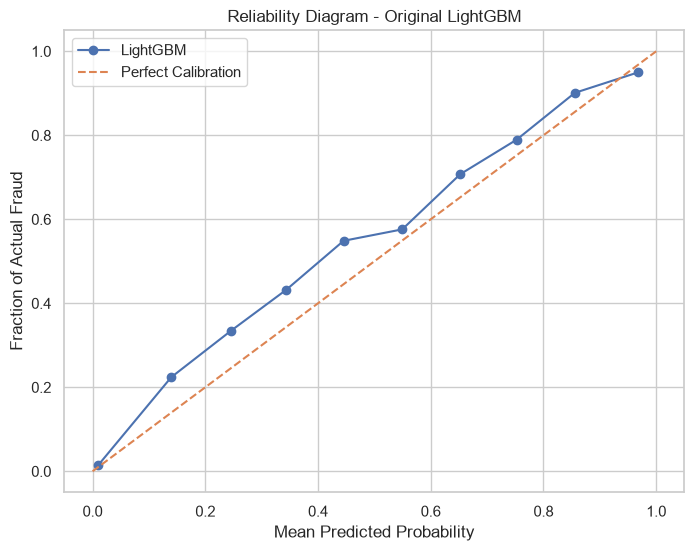

In [31]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Calculate calibration data
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_val,
    y_val_proba,
    n_bins=10,
    strategy="uniform"
)

# Brier score
brier = brier_score_loss(y_val, y_val_proba)

print("Original Model Brier Score:", brier)

# Plot reliability diagram
plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label="LightGBM"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Actual Fraud")
plt.title("Reliability Diagram - Original LightGBM")
plt.legend()
plt.grid(True)
plt.show()

In [32]:
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from scipy.special import logit

# Split validation data chronologically
cal_split = len(y_val) // 2

# First half: calibration fitting
y_cal = y_val.iloc[:cal_split]
proba_cal = y_val_proba[:cal_split]

# Second half: independent evaluation
y_eval = y_val.iloc[cal_split:]
proba_eval = y_val_proba[cal_split:]

print("Calibration samples:", len(y_cal))
print("Evaluation samples:", len(y_eval))
print("Calibration fraud cases:", y_cal.sum())
print("Evaluation fraud cases:", y_eval.sum())

Calibration samples: 44290
Evaluation samples: 44291
Calibration fraud cases: 1593
Evaluation fraud cases: 1449


In [33]:
# Prepare model scores for Platt Scaling
eps = 1e-7

cal_logits = logit(
    np.clip(proba_cal, eps, 1 - eps)
)

eval_logits = logit(
    np.clip(proba_eval, eps, 1 - eps)
)

# Platt Scaling
platt_model = LogisticRegression()

platt_model.fit(
    cal_logits.reshape(-1, 1),
    y_cal
)

platt_proba = platt_model.predict_proba(
    eval_logits.reshape(-1, 1)
)[:, 1]

# Isotonic Regression
isotonic_model = IsotonicRegression(
    out_of_bounds="clip"
)

isotonic_model.fit(
    proba_cal,
    y_cal
)

isotonic_proba = isotonic_model.predict(
    proba_eval
)

print("Platt Scaling completed!")
print("Isotonic Regression completed!")

Platt Scaling completed!
Isotonic Regression completed!


In [34]:
calibration_results = pd.DataFrame({
    "Model": [
        "Original LightGBM",
        "Platt Scaling",
        "Isotonic Regression"
    ],
    "Brier Score": [
        brier_score_loss(y_eval, proba_eval),
        brier_score_loss(y_eval, platt_proba),
        brier_score_loss(y_eval, isotonic_proba)
    ]
})

display(
    calibration_results.sort_values(
        by="Brier Score"
    ).round(6)
)

,Model,Brier Score
1,Platt Scaling,0.022190
2,Isotonic Regression,0.022230
0,Original LightGBM,0.022334


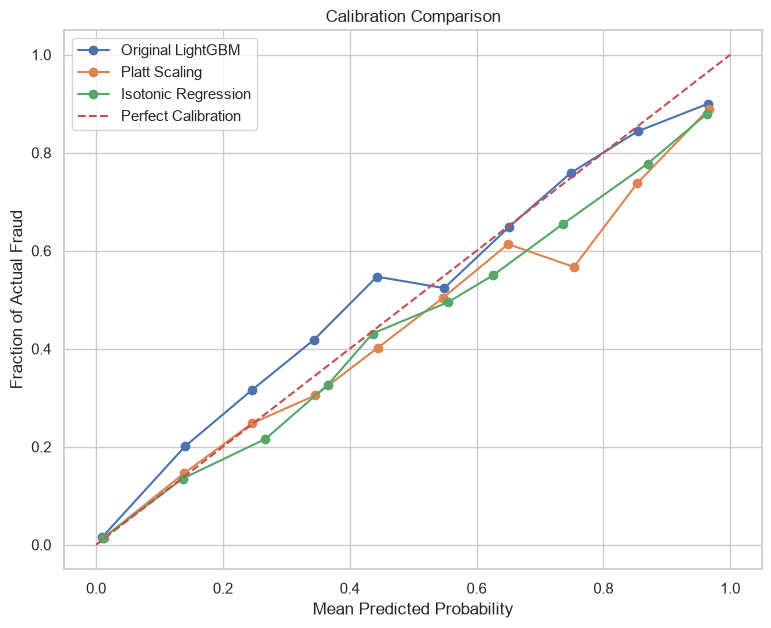

In [35]:
plt.figure(figsize=(9, 7))

for name, probabilities in [
    ("Original LightGBM", proba_eval),
    ("Platt Scaling", platt_proba),
    ("Isotonic Regression", isotonic_proba)
]:

    fraction_positive, mean_predicted = calibration_curve(
        y_eval,
        probabilities,
        n_bins=10,
        strategy="uniform"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Actual Fraud")
plt.title("Calibration Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [36]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

comparison = []

for name, probabilities in [
    ("Original LightGBM", proba_eval),
    ("Platt Scaling", platt_proba),
    ("Isotonic Regression", isotonic_proba)
]:

    comparison.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_eval, probabilities),
        "Average Precision": average_precision_score(y_eval, probabilities),
        "Brier Score": brier_score_loss(y_eval, probabilities),
        "Log Loss": log_loss(y_eval, probabilities)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(6))

,Model,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Original LightGBM,0.903255,0.492417,0.022334,0.091513
1,Platt Scaling,0.903255,0.492417,0.022190,0.090295
2,Isotonic Regression,0.902598,0.473764,0.022230,0.091737


In [37]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    recall_score
)

# Six consecutive chronological windows
n_windows = 6

window_indices = np.array_split(
    np.arange(len(y_val)),
    n_windows
)

drift_results = []

for i, indices in enumerate(window_indices):

    actual = y_val.iloc[indices]
    probabilities = y_val_proba[indices]

    predictions = (
        probabilities >= BEST_THRESHOLD
    ).astype(int)

    drift_results.append({

        "Window": f"Window {i + 1}",

        "Start_Time": val_set["TransactionDT"].iloc[indices[0]],

        "End_Time": val_set["TransactionDT"].iloc[indices[-1]],

        "Transactions": len(indices),

        "Fraud_Count": int(actual.sum()),

        "Fraud_Rate": actual.mean(),

        "ROC_AUC": roc_auc_score(
            actual, probabilities
        ),

        "Average_Precision": average_precision_score(
            actual, probabilities
        ),

        "Brier_Score": brier_score_loss(
            actual, probabilities
        ),

        "Recall": recall_score(
            actual, predictions,
            zero_division=0
        )
    })

drift_df = pd.DataFrame(drift_results)

display(drift_df.round(4))

,Window,Start_Time,End_Time,Transactions,Fraud_Count,Fraud_Rate,ROC_AUC,Average_Precision,Brier_Score,Recall
0,Window 1,10438003,10809110,14764,474,0.0321,0.9341,0.7028,0.0153,0.6034
1,Window 2,10809162,11246665,14764,551,0.0373,0.9374,0.6893,0.0188,0.5590
2,Window 3,11246704,11725727,14764,568,0.0385,0.9161,0.5881,0.0232,0.4648
3,Window 4,11725745,12192900,14763,469,0.0318,0.9204,0.5246,0.0210,0.4499
4,Window 5,12192911,12690519,14763,535,0.0362,0.8974,0.4921,0.0250,0.3776
5,Window 6,12690525,13151840,14763,445,0.0301,0.8932,0.4681,0.0209,0.4247


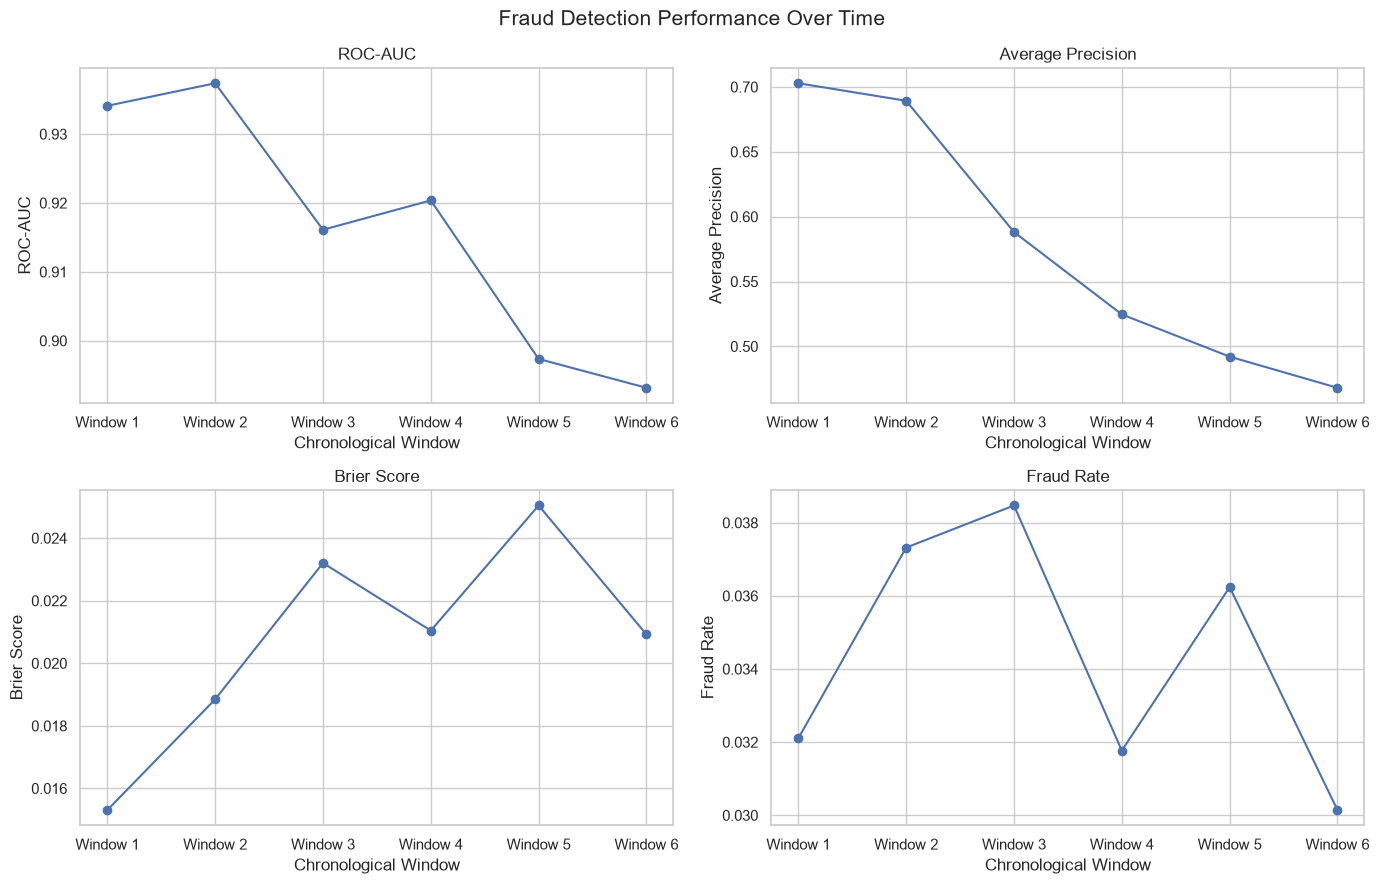

In [38]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

metrics = [
    ("ROC_AUC", "ROC-AUC"),
    ("Average_Precision", "Average Precision"),
    ("Brier_Score", "Brier Score"),
    ("Fraud_Rate", "Fraud Rate")
]

for ax, (column, title) in zip(axes.flat, metrics):

    ax.plot(
        drift_df["Window"],
        drift_df[column],
        marker="o"
    )

    ax.set_title(title)
    ax.set_xlabel("Chronological Window")
    ax.set_ylabel(title)
    ax.grid(True)

plt.suptitle(
    "Fraud Detection Performance Over Time",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [41]:
# Get LightGBM feature importance

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

top_features = importance_df.head(10)["Feature"].tolist()

display(importance_df.head(10))

,Feature,Importance
431,DeviceInfo,926
3,card1,885
4,card2,874
9,addr1,789
0,TransactionDT,765
1,TransactionAmt,635
422,id_31,560
13,P_emaildomain,458
43,D15,429
27,C13,380


In [42]:
def calculate_psi(reference, comparison, bins=10):

    reference = pd.to_numeric(
        reference, errors="coerce"
    ).to_numpy(dtype=float)

    comparison = pd.to_numeric(
        comparison, errors="coerce"
    ).to_numpy(dtype=float)

    reference_valid = reference[np.isfinite(reference)]

    if len(reference_valid) == 0:
        return np.nan

    # Define bins using reference data only
    quantiles = np.linspace(0, 1, bins + 1)

    edges = np.unique(
        np.quantile(reference_valid, quantiles)
    )

    if len(edges) < 2:
        return np.nan

    edges[0] = -np.inf
    edges[-1] = np.inf

    # Assign observations to bins
    ref_bins = np.searchsorted(
        edges[1:-1],
        reference_valid,
        side="right"
    )

    comp_valid = comparison[np.isfinite(comparison)]

    comp_bins = np.searchsorted(
        edges[1:-1],
        comp_valid,
        side="right"
    )

    # Add one additional bucket for missing values
    n_bins = len(edges) - 1

    ref_counts = np.bincount(
        ref_bins,
        minlength=n_bins
    )

    comp_counts = np.bincount(
        comp_bins,
        minlength=n_bins
    )

    ref_missing = len(reference) - len(reference_valid)
    comp_missing = len(comparison) - len(comp_valid)

    ref_counts = np.append(ref_counts, ref_missing)
    comp_counts = np.append(comp_counts, comp_missing)

    # Calculate proportions with smoothing
    epsilon = 1e-6

    ref_pct = (
        ref_counts + epsilon
    ) / (
        ref_counts.sum() + epsilon * len(ref_counts)
    )

    comp_pct = (
        comp_counts + epsilon
    ) / (
        comp_counts.sum() + epsilon * len(comp_counts)
    )

    psi = np.sum(
        (comp_pct - ref_pct) *
        np.log(comp_pct / ref_pct)
    )

    return psi

In [43]:
psi_results = []

for feature in top_features:

    reference = X_train[feature]

    for i, indices in enumerate(window_indices):

        comparison = X_val.iloc[indices][feature]

        psi_value = calculate_psi(
            reference,
            comparison
        )

        psi_results.append({
            "Feature": feature,
            "Window": f"Window {i + 1}",
            "PSI": psi_value
        })

psi_df = pd.DataFrame(psi_results)

psi_pivot = psi_df.pivot(
    index="Feature",
    columns="Window",
    values="PSI"
)

display(psi_pivot.round(4))

Window,Window 1,Window 2,Window 3,Window 4,Window 5,Window 6
Feature,,,,,,
C13,0.0508,0.0304,0.0269,0.0370,0.0340,0.0281
D15,0.1609,0.0487,0.1093,0.0708,0.0744,0.1241
DeviceInfo,NaN,NaN,NaN,NaN,NaN,NaN
P_emaildomain,NaN,NaN,NaN,NaN,NaN,NaN
TransactionAmt,0.0122,0.0115,0.0056,0.0125,0.0092,0.0102
TransactionDT,21.0739,21.0739,21.0739,21.0738,21.0738,21.0738
addr1,0.0033,0.0027,0.0034,0.0020,0.0117,0.0052
card1,0.0176,0.0032,0.0016,0.0018,0.0035,0.0046
card2,0.0282,0.0120,0.0083,0.0123,0.0098,0.0123


In [44]:
# Identify numerical top features
numeric_top_features = [
    feature for feature in top_features
    if pd.api.types.is_numeric_dtype(X_train[feature])
    and feature != "TransactionDT"
]

print("Numerical features for PSI:")
print(numeric_top_features)

Numerical features for PSI:
['card1', 'card2', 'addr1', 'TransactionAmt', 'D15', 'C13']


In [45]:
numeric_psi_results = []

for feature in numeric_top_features:

    reference = X_train[feature]

    for i, indices in enumerate(window_indices):

        comparison = X_val.iloc[indices][feature]

        psi_value = calculate_psi(
            reference,
            comparison
        )

        numeric_psi_results.append({
            "Feature": feature,
            "Window": f"Window {i + 1}",
            "PSI": psi_value
        })

numeric_psi_df = pd.DataFrame(numeric_psi_results)

numeric_psi_pivot = numeric_psi_df.pivot(
    index="Feature",
    columns="Window",
    values="PSI"
)

display(numeric_psi_pivot.round(4))

Window,Window 1,Window 2,Window 3,Window 4,Window 5,Window 6
Feature,,,,,,
C13,0.0508,0.0304,0.0269,0.0370,0.0340,0.0281
D15,0.1609,0.0487,0.1093,0.0708,0.0744,0.1241
TransactionAmt,0.0122,0.0115,0.0056,0.0125,0.0092,0.0102
addr1,0.0033,0.0027,0.0034,0.0020,0.0117,0.0052
card1,0.0176,0.0032,0.0016,0.0018,0.0035,0.0046
card2,0.0282,0.0120,0.0083,0.0123,0.0098,0.0123


In [46]:
def calculate_categorical_psi(reference, comparison, top_n=50):

    reference = reference.astype("string").fillna("MISSING")
    comparison = comparison.astype("string").fillna("MISSING")

    # Keep the most frequent reference categories
    top_categories = (
        reference.value_counts()
        .head(top_n)
        .index
        .tolist()
    )

    def group_categories(series):
        return series.where(
            (series == "MISSING") |
            (series.isin(top_categories)),
            "OTHER"
        )

    reference = group_categories(reference)
    comparison = group_categories(comparison)

    # Use the union of categories from both datasets
    categories = sorted(
        set(reference.unique()) |
        set(comparison.unique())
    )

    ref_counts = reference.value_counts().reindex(
        categories, fill_value=0
    )

    comp_counts = comparison.value_counts().reindex(
        categories, fill_value=0
    )

    epsilon = 1e-6

    ref_pct = (
        ref_counts + epsilon
    ) / (
        len(reference) + epsilon * len(categories)
    )

    comp_pct = (
        comp_counts + epsilon
    ) / (
        len(comparison) + epsilon * len(categories)
    )

    psi = np.sum(
        (comp_pct - ref_pct) *
        np.log(comp_pct / ref_pct)
    )

    return psi

In [47]:
categorical_top_features = [
    feature for feature in top_features
    if (
        pd.api.types.is_object_dtype(X_train[feature])
        or isinstance(X_train[feature].dtype, pd.CategoricalDtype)
    )
]

print("Categorical features:")
print(categorical_top_features)

categorical_psi_results = []

for feature in categorical_top_features:

    reference = X_train[feature]

    for i, indices in enumerate(window_indices):

        comparison = X_val.iloc[indices][feature]

        psi_value = calculate_categorical_psi(
            reference,
            comparison
        )

        categorical_psi_results.append({
            "Feature": feature,
            "Window": f"Window {i + 1}",
            "PSI": psi_value
        })

categorical_psi_df = pd.DataFrame(
    categorical_psi_results
)

if not categorical_psi_df.empty:

    categorical_psi_pivot = categorical_psi_df.pivot(
        index="Feature",
        columns="Window",
        values="PSI"
    )

    display(categorical_psi_pivot.round(4))

Categorical features:
['DeviceInfo', 'id_31', 'P_emaildomain']


Window,Window 1,Window 2,Window 3,Window 4,Window 5,Window 6
Feature,,,,,,
DeviceInfo,0.1295,0.1375,0.1060,0.1237,0.1529,0.1217
P_emaildomain,0.0147,0.0126,0.0120,0.0076,0.0101,0.0096
id_31,1.3766,1.3464,1.4024,1.4161,1.3086,1.3429


In [48]:
from scipy.stats import ks_2samp

ks_features = numeric_top_features

ks_results = []

for feature in ks_features:

    reference = X_train[feature].dropna()

    for i, indices in enumerate(window_indices):

        comparison = X_val.iloc[indices][feature].dropna()

        statistic, p_value = ks_2samp(
            reference,
            comparison
        )

        ks_results.append({
            "Feature": feature,
            "Window": f"Window {i + 1}",
            "KS_Statistic": statistic,
            "P_Value": p_value
        })

ks_df = pd.DataFrame(ks_results)

display(
    ks_df.round(6)
)

,Feature,Window,KS_Statistic,P_Value
0,card1,Window 1,0.029834,0.000000
1,card1,Window 2,0.010114,0.107497
2,card1,Window 3,0.012387,0.024983
3,card1,Window 4,0.017943,0.000204
4,card1,Window 5,0.020418,0.000014
5,card1,Window 6,0.019087,0.000061
6,card2,Window 1,0.039756,0.000000
7,card2,Window 2,0.026370,0.000000
8,card2,Window 3,0.015644,0.001975
9,card2,Window 4,0.023411,0.000000


In [49]:
from statsmodels.stats.multitest import multipletests

ks_df["Adjusted_P_Value"] = multipletests(
    ks_df["P_Value"],
    method="fdr_bh"
)[1]

ks_df["Drift_Detected"] = (
    ks_df["Adjusted_P_Value"] < 0.05
)

display(
    ks_df.sort_values(
        by="Adjusted_P_Value"
    ).round(6)
)

ModuleNotFoundError: No module named 'statsmodels'

In [50]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.3 MB 3.7 MB/s eta 0:00:03
   ----- ---------------------------------- 1.6/11.3 MB 3.2 MB/s eta 0:00:04
   -------- ------------------------------- 2.4/11.3 MB 3.4 MB/s eta 0:00:03
   ----------- ---------------------------- 3.1/11.3 MB 3.4 MB/s eta 0:00:03
   -------------- ------------------------- 4.2/11.3 MB 3.7 MB/s eta 0:00:02
   -------------------- ------------------- 5.8/11.3 MB 4.3 MB/s eta 0:00:02
   ------------------------- -------------- 7.1/11.3 MB 4.6 MB/s eta 0:00:01
   ----------------------------- ---------- 8.4/11.3 MB 4.9 MB/s eta 0:00:01
   ----------------------------------- ---- 10.0/11.3 MB 5.1 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 5.4 MB/s  0:00:02

   ---------------------------------------- 0/5 [wrapt]
   -------- ----------------------

In [51]:
from statsmodels.stats.multitest import multipletests

ks_df["Adjusted_P_Value"] = multipletests(
    ks_df["P_Value"],
    method="fdr_bh"
)[1]

ks_df["Drift_Detected"] = (
    ks_df["Adjusted_P_Value"] < 0.05
)

display(
    ks_df.sort_values(
        by="Adjusted_P_Value"
    ).round(6)
)

,Feature,Window,KS_Statistic,P_Value,Adjusted_P_Value,Drift_Detected
30,C13,Window 1,0.102563,0.000000,0.000000,True
27,D15,Window 4,0.097125,0.000000,0.000000,True
29,D15,Window 6,0.095247,0.000000,0.000000,True
26,D15,Window 3,0.104116,0.000000,0.000000,True
33,C13,Window 4,0.089823,0.000000,0.000000,True
28,D15,Window 5,0.093235,0.000000,0.000000,True
34,C13,Window 5,0.087791,0.000000,0.000000,True
24,D15,Window 1,0.088042,0.000000,0.000000,True
31,C13,Window 2,0.082108,0.000000,0.000000,True
35,C13,Window 6,0.080340,0.000000,0.000000,True


In [52]:
drift_features = ["D15", "C13"]

feature_bins = {}

for feature in drift_features:

    # Learn boundaries from training data only
    _, bin_edges = pd.qcut(
        X_train[feature],
        q=5,
        retbins=True,
        duplicates="drop"
    )

    # Extend boundaries to include future values
    bin_edges[0] = -np.inf
    bin_edges[-1] = np.inf

    feature_bins[feature] = bin_edges

print("Training-based feature bins created!")

Training-based feature bins created!


In [53]:
conditional_results = []

for feature in drift_features:

    edges = feature_bins[feature]

    for i, indices in enumerate(window_indices):

        window_features = X_val.iloc[indices][feature]

        window_labels = y_val.iloc[indices]

        bins = pd.cut(
            window_features,
            bins=edges,
            include_lowest=True
        )

        temp = pd.DataFrame({
            "Feature_Bin": bins,
            "isFraud": window_labels.to_numpy()
        })

        grouped = temp.groupby(
            "Feature_Bin",
            observed=False
        )["isFraud"].agg(
            Fraud_Rate="mean",
            Transaction_Count="count",
            Fraud_Count="sum"
        )

        for bin_name, row in grouped.iterrows():

            conditional_results.append({

                "Feature": feature,
                "Window": f"Window {i + 1}",
                "Feature_Bin": str(bin_name),

                "Fraud_Rate": row["Fraud_Rate"],

                "Transaction_Count": row["Transaction_Count"],

                "Fraud_Count": row["Fraud_Count"]
            })

conditional_df = pd.DataFrame(conditional_results)

display(
    conditional_df.round(4)
)

,Feature,Window,Feature_Bin,Fraud_Rate,Transaction_Count,Fraud_Count
0,D15,Window 1,"(-inf, 0.0]",0.0448,4287.0,192.0
1,D15,Window 1,"(0.0, 5.0]",0.0358,363.0,13.0
2,D15,Window 1,"(5.0, 114.0]",0.0253,3001.0,76.0
3,D15,Window 1,"(114.0, 365.0]",0.0313,2874.0,90.0
4,D15,Window 1,"(365.0, inf]",0.0110,3349.0,37.0
5,D15,Window 2,"(-inf, 0.0]",0.0477,3566.0,170.0
6,D15,Window 2,"(0.0, 5.0]",0.1072,345.0,37.0
7,D15,Window 2,"(5.0, 114.0]",0.0311,2542.0,79.0
8,D15,Window 2,"(114.0, 365.0]",0.0087,2403.0,21.0
9,D15,Window 2,"(365.0, inf]",0.0113,2822.0,32.0


In [54]:
from scipy.stats import chi2_contingency

conditional_test_results = []

for feature in drift_features:

    feature_data = conditional_df[
        conditional_df["Feature"] == feature
    ]

    for bin_name in feature_data["Feature_Bin"].unique():

        group_data = feature_data[
            feature_data["Feature_Bin"] == bin_name
        ].copy()

        # Exclude groups with insufficient observations
        if (group_data["Transaction_Count"] < 100).any():
            continue

        group_data["Legitimate_Count"] = (
            group_data["Transaction_Count"]
            - group_data["Fraud_Count"]
        )

        contingency_table = group_data[
            ["Fraud_Count", "Legitimate_Count"]
        ].to_numpy()

        chi2, p_value, dof, expected = chi2_contingency(
            contingency_table
        )

        conditional_test_results.append({

            "Feature": feature,
            "Feature_Bin": bin_name,
            "Chi2_Statistic": chi2,
            "P_Value": p_value,
            "Degrees_of_Freedom": dof

        })

conditional_test_df = pd.DataFrame(
    conditional_test_results
)

display(conditional_test_df.round(6))

,Feature,Feature_Bin,Chi2_Statistic,P_Value,Degrees_of_Freedom
0,D15,"(-inf, 0.0]",6.135901,0.293219,5
1,D15,"(0.0, 5.0]",27.927375,0.000038,5
2,D15,"(5.0, 114.0]",27.529050,0.000045,5
3,D15,"(114.0, 365.0]",71.279470,0.000000,5
4,D15,"(365.0, inf]",10.459830,0.063207,5
5,C13,"(-inf, 1.0]",40.838758,0.000000,5
6,C13,"(1.0, 4.0]",23.562451,0.000263,5
7,C13,"(4.0, 16.0]",32.859307,0.000004,5
8,C13,"(16.0, inf]",15.512071,0.008384,5


In [55]:
conditional_test_df["Adjusted_P_Value"] = multipletests(
    conditional_test_df["P_Value"],
    method="fdr_bh"
)[1]

conditional_test_df["Relationship_Change"] = (
    conditional_test_df["Adjusted_P_Value"] < 0.05
)

display(
    conditional_test_df.sort_values(
        "Adjusted_P_Value"
    ).round(6)
)

,Feature,Feature_Bin,Chi2_Statistic,P_Value,Degrees_of_Freedom,Adjusted_P_Value,Relationship_Change
3,D15,"(114.0, 365.0]",71.279470,0.000000,5,0.000000,True
5,C13,"(-inf, 1.0]",40.838758,0.000000,5,0.000000,True
7,C13,"(4.0, 16.0]",32.859307,0.000004,5,0.000012,True
1,D15,"(0.0, 5.0]",27.927375,0.000038,5,0.000081,True
2,D15,"(5.0, 114.0]",27.529050,0.000045,5,0.000081,True
6,C13,"(1.0, 4.0]",23.562451,0.000263,5,0.000395,True
8,C13,"(16.0, inf]",15.512071,0.008384,5,0.010780,True
4,D15,"(365.0, inf]",10.459830,0.063207,5,0.071107,False
0,D15,"(-inf, 0.0]",6.135901,0.293219,5,0.293219,False


In [56]:
# Summarize significant relationship changes

significant_groups = conditional_test_df[
    conditional_test_df["Relationship_Change"] == True
]

drift_summary = (
    significant_groups
    .groupby("Feature")
    .agg(
        Total_Groups_Tested=("Feature_Bin", "count"),
        Significant_Groups=("Relationship_Change", "sum"),
        Strongest_Chi2=("Chi2_Statistic", "max"),
        Lowest_Adjusted_P=("Adjusted_P_Value", "min")
    )
    .reset_index()
)

display(drift_summary.round(6))

print(
    "Total significant groups:",
    len(significant_groups),
    "out of",
    len(conditional_test_df)
)

,Feature,Total_Groups_Tested,Significant_Groups,Strongest_Chi2,Lowest_Adjusted_P
0,C13,4,4,40.838758,0.0
1,D15,3,3,71.279470,0.0


Total significant groups: 7 out of 9


In [57]:
import joblib
import os

MODEL_PATH = "../models/"

os.makedirs(MODEL_PATH, exist_ok=True)

joblib.dump(
    model,
    MODEL_PATH + "lightgbm_baseline.pkl"
)

print("Baseline LightGBM model saved successfully!")

Baseline LightGBM model saved successfully!


In [58]:
import joblib
import os

MODEL_PATH = "../models/"

joblib.dump(
    platt_model,
    MODEL_PATH + "platt_scaling.pkl"
)

joblib.dump(
    isotonic_model,
    MODEL_PATH + "isotonic_regression.pkl"
)

print("Both calibration models saved successfully!")

Both calibration models saved successfully!


In [59]:
import os

RESULTS_PATH = "../results/"
os.makedirs(RESULTS_PATH, exist_ok=True)

# DataFrames generated during our experiments
result_tables = {
    "model_comparison": "comparison_dt",
    "feature_importance": "importance_df",
    "conditional_drift_tests": "conditional_test_df",
    "drift_summary": "drift_summary",
    "numeric_psi": "numeric_psi_pivot",
    "categorical_psi": "categorical_psi_pivot",
    "psi_results": "psi_pivot"
}

saved_files = []

for filename, variable_name in result_tables.items():

    if variable_name in globals():
        globals()[variable_name].to_csv(
            RESULTS_PATH + filename + ".csv",
            index=True
        )
        saved_files.append(filename + ".csv")

print("Experiment results saved:")
for filename in saved_files:
    print(" -", filename)

Experiment results saved:
 - feature_importance.csv
 - conditional_drift_tests.csv
 - drift_summary.csv
 - numeric_psi.csv
 - categorical_psi.csv
 - psi_results.csv


In [60]:
import os
import matplotlib.pyplot as plt

RESULTS_PATH = "../results/"
os.makedirs(RESULTS_PATH, exist_ok=True)

for i in plt.get_fignums():

    fig = plt.figure(i)

    fig.savefig(
        RESULTS_PATH + f"experiment_plot_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("All available experiment plots saved!")

All available experiment plots saved!


In [61]:
comparison_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")
display(comparison_df.round(6))

Model comparison saved successfully!


,Model,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Original LightGBM,0.903255,0.492417,0.022334,0.091513
1,Platt Scaling,0.903255,0.492417,0.022190,0.090295
2,Isotonic Regression,0.902598,0.473764,0.022230,0.091737


In [62]:
import os
from pathlib import Path

RESULTS_PATH = Path("../results")

print("Results folder:", RESULTS_PATH.resolve())
print("Folder exists:", RESULTS_PATH.exists())

plot_files = sorted(RESULTS_PATH.glob("experiment_plot_*.png"))

print("\nTotal saved experiment plots:", len(plot_files))

for file in plot_files:
    size_kb = file.stat().st_size / 1024
    print(f"{file.name} - {size_kb:.2f} KB")

Results folder: D:\Fraud-Detection\results
Folder exists: True

Total saved experiment plots: 0


In [63]:
from pathlib import Path

RESULTS_PATH = Path("../results")

all_files = sorted(RESULTS_PATH.iterdir())

print("TOTAL FILES:", len(all_files))
print("\nFILES IN RESULTS FOLDER:\n")

for file in all_files:
    if file.is_file():
        size_kb = file.stat().st_size / 1024
        print(f"{file.name:40} {size_kb:10.2f} KB")
    else:
        print(f"{file.name}/  [Folder]")

TOTAL FILES: 7

FILES IN RESULTS FOLDER:

categorical_psi.csv                            0.44 KB
conditional_drift_tests.csv                    0.89 KB
drift_summary.csv                              0.18 KB
feature_importance.csv                         5.17 KB
model_comparison.csv                           0.34 KB
numeric_psi.csv                                0.84 KB
psi_results.csv                                1.01 KB


In [64]:
import matplotlib.pyplot as plt

open_figures = plt.get_fignums()

print("Currently open Matplotlib figures:", len(open_figures))
print("Figure numbers:", open_figures)

Currently open Matplotlib figures: 0
Figure numbers: []


In [65]:
from pathlib import Path
import pandas as pd

RESULTS_PATH = Path("../results")

csv_files = [
    "feature_importance.csv",
    "conditional_drift_tests.csv",
    "drift_summary.csv",
    "numeric_psi.csv",
    "categorical_psi.csv",
    "psi_results.csv",
    "model_comparison.csv"
]

for filename in csv_files:
    file_path = RESULTS_PATH / filename

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("=" * 70)

    df = pd.read_csv(file_path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


FILE: feature_importance.csv
Shape: (432, 3)
Columns: ['Unnamed: 0', 'Feature', 'Importance']


,Unnamed: 0,Feature,Importance
0,431,DeviceInfo,926
1,3,card1,885
2,4,card2,874



FILE: conditional_drift_tests.csv
Shape: (9, 8)
Columns: ['Unnamed: 0', 'Feature', 'Feature_Bin', 'Chi2_Statistic', 'P_Value', 'Degrees_of_Freedom', 'Adjusted_P_Value', 'Relationship_Change']


,Unnamed: 0,Feature,Feature_Bin,Chi2_Statistic,P_Value,Degrees_of_Freedom,Adjusted_P_Value,Relationship_Change
0,0,D15,"(-inf, 0.0]",6.135901,0.293219,5,0.293219,False
1,1,D15,"(0.0, 5.0]",27.927375,0.000038,5,0.000081,True
2,2,D15,"(5.0, 114.0]",27.529050,0.000045,5,0.000081,True



FILE: drift_summary.csv
Shape: (2, 6)
Columns: ['Unnamed: 0', 'Feature', 'Total_Groups_Tested', 'Significant_Groups', 'Strongest_Chi2', 'Lowest_Adjusted_P']


,Unnamed: 0,Feature,Total_Groups_Tested,Significant_Groups,Strongest_Chi2,Lowest_Adjusted_P
0,0,C13,4,4,40.838758,4.551062e-07
1,1,D15,3,3,71.279470,4.994762e-13


... (4 outputs left out)


FILE: psi_results.csv
Shape: (10, 7)
Columns: ['Feature', 'Window 1', 'Window 2', 'Window 3', 'Window 4', 'Window 5', 'Window 6']


,Feature,Window 1,Window 2,Window 3,Window 4,Window 5,Window 6
0,C13,0.050786,0.030389,0.026879,0.037035,0.034013,0.028130
1,D15,0.160881,0.048659,0.109271,0.070829,0.074360,0.124052
2,DeviceInfo,NaN,NaN,NaN,NaN,NaN,NaN



FILE: model_comparison.csv
Shape: (3, 5)
Columns: ['Model', 'ROC-AUC', 'Average Precision', 'Brier Score', 'Log Loss']


,Model,ROC-AUC,Average Precision,Brier Score,Log Loss
0,Original LightGBM,0.903255,0.492417,0.022334,0.091513
1,Platt Scaling,0.903255,0.492417,0.022190,0.090295
2,Isotonic Regression,0.902598,0.473764,0.022230,0.091737


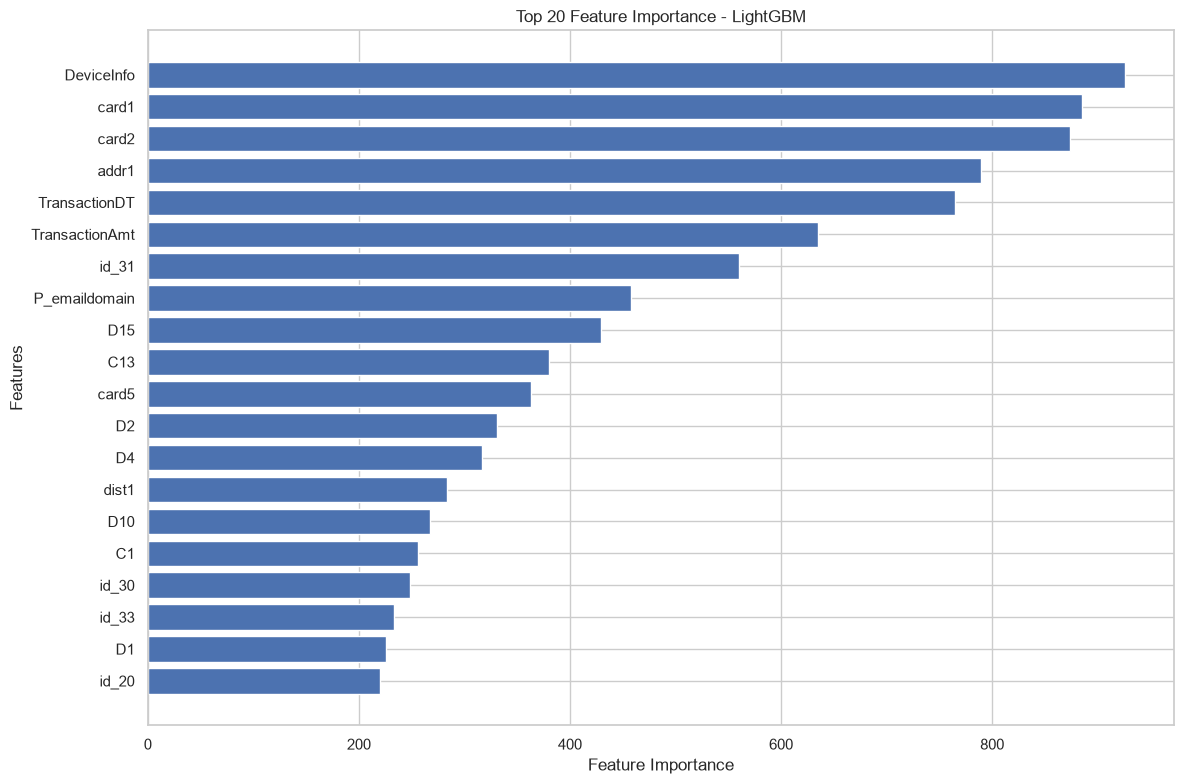

Feature importance plot saved successfully!


In [66]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_PATH = Path("../results")

# Load feature importance
importance_df = pd.read_csv(
    RESULTS_PATH / "feature_importance.csv"
)

# Remove unnecessary CSV index column
importance_df = importance_df.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

# Select top 20 features
top_20 = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(20)

# Plot
plt.figure(figsize=(12, 8))

plt.barh(
    top_20["Feature"][::-1],
    top_20["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 20 Feature Importance - LightGBM")
plt.tight_layout()

# Save
plt.savefig(
    RESULTS_PATH / "experiment_plot_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance plot saved successfully!")

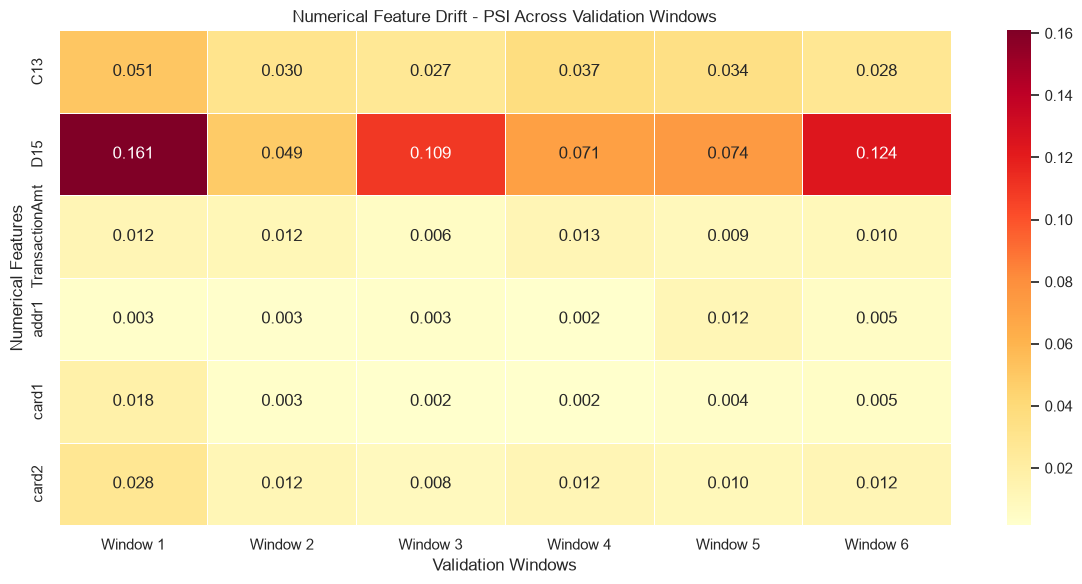

Numerical PSI heatmap saved successfully!


In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RESULTS_PATH = Path("../results")

numeric_psi_df = pd.read_csv(
    RESULTS_PATH / "numeric_psi.csv"
)

numeric_psi_df = numeric_psi_df.set_index("Feature")

plt.figure(figsize=(12, 6))

sns.heatmap(
    numeric_psi_df,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Numerical Feature Drift - PSI Across Validation Windows")
plt.xlabel("Validation Windows")
plt.ylabel("Numerical Features")
plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "experiment_plot_numeric_psi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Numerical PSI heatmap saved successfully!")

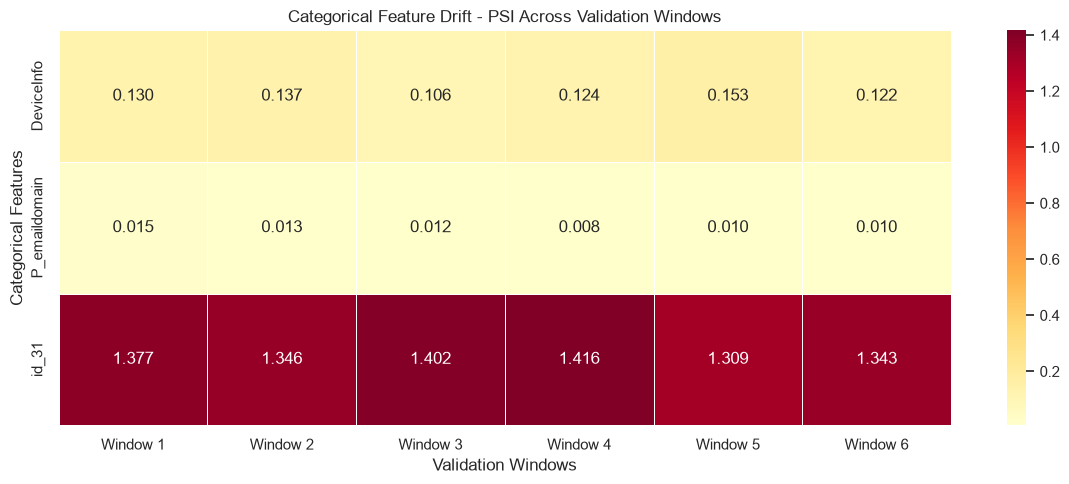

Categorical PSI heatmap saved successfully!


In [68]:
categorical_psi_df = pd.read_csv(
    RESULTS_PATH / "categorical_psi.csv"
)

categorical_psi_df = categorical_psi_df.set_index("Feature")

plt.figure(figsize=(12, 5))

sns.heatmap(
    categorical_psi_df,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Categorical Feature Drift - PSI Across Validation Windows")
plt.xlabel("Validation Windows")
plt.ylabel("Categorical Features")
plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "experiment_plot_categorical_psi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Categorical PSI heatmap saved successfully!")

In [69]:
required_variables = [
    "window_indices",
    "y_val",
    "y_val_proba",
    "model",
    "BEST_THRESHOLD"
]

for variable in required_variables:
    print(
        variable,
        "->",
        "Available" if variable in globals() else "Missing"
    )

window_indices -> Available
y_val -> Available
y_val_proba -> Available
model -> Available
BEST_THRESHOLD -> Available


In [70]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    recall_score,
    brier_score_loss
)

window_results = []

for i, indices in enumerate(window_indices, start=1):

    y_window = y_val.iloc[indices]
    proba_window = y_val_proba[indices]

    pred_window = (
        proba_window >= BEST_THRESHOLD
    ).astype(int)

    window_results.append({
        "Window": f"Window {i}",
        "Fraud_Rate": y_window.mean(),
        "ROC_AUC": roc_auc_score(
            y_window, proba_window
        ),
        "Average_Precision": average_precision_score(
            y_window, proba_window
        ),
        "Recall": recall_score(
            y_window, pred_window,
            zero_division=0
        ),
        "Brier_Score": brier_score_loss(
            y_window, proba_window
        )
    })

window_performance_df = pd.DataFrame(window_results)

display(
    window_performance_df.round(4)
)

,Window,Fraud_Rate,ROC_AUC,Average_Precision,Recall,Brier_Score
0,Window 1,0.0321,0.9341,0.7028,0.6034,0.0153
1,Window 2,0.0373,0.9374,0.6893,0.5590,0.0188
2,Window 3,0.0385,0.9161,0.5881,0.4648,0.0232
3,Window 4,0.0318,0.9204,0.5246,0.4499,0.0210
4,Window 5,0.0362,0.8974,0.4921,0.3776,0.0250
5,Window 6,0.0301,0.8932,0.4681,0.4247,0.0209


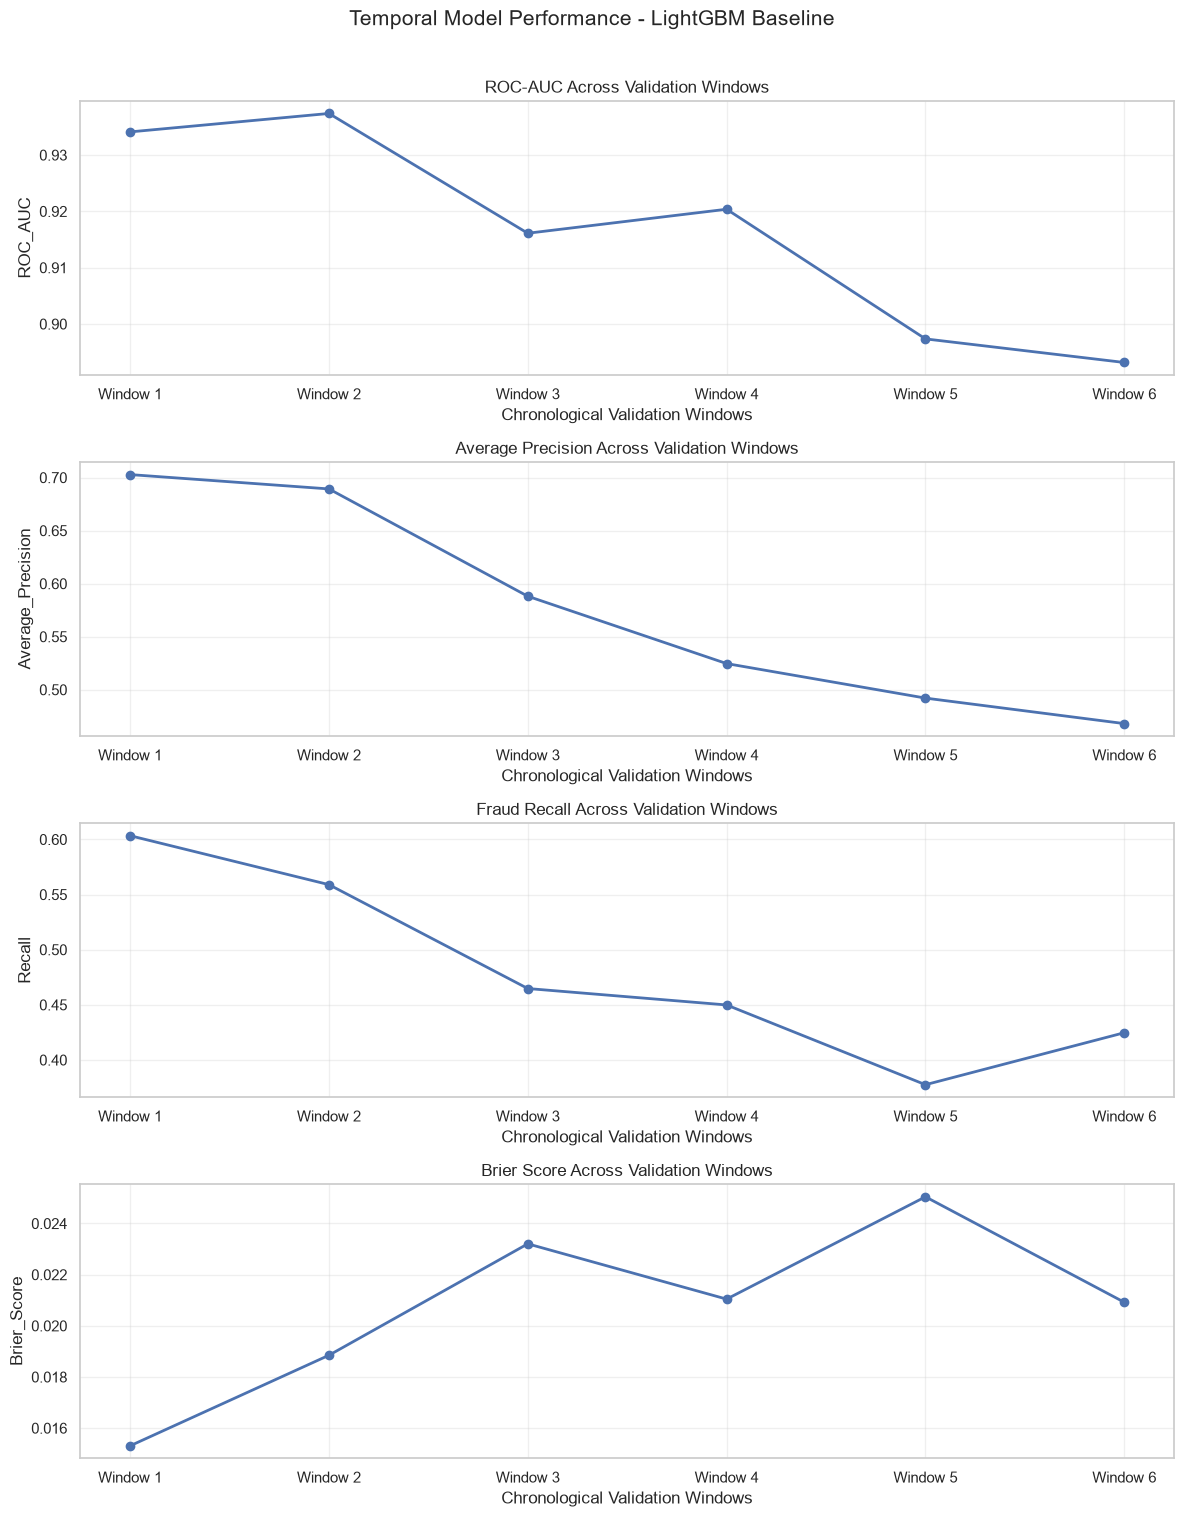

Temporal performance plot saved successfully!


In [71]:
fig, axes = plt.subplots(4, 1, figsize=(12, 15))

metrics = [
    ("ROC_AUC", "ROC-AUC Across Validation Windows"),
    ("Average_Precision", "Average Precision Across Validation Windows"),
    ("Recall", "Fraud Recall Across Validation Windows"),
    ("Brier_Score", "Brier Score Across Validation Windows")
]

for ax, (column, title) in zip(axes, metrics):
    ax.plot(
        window_performance_df["Window"],
        window_performance_df[column],
        marker="o",
        linewidth=2
    )

    ax.set_title(title)
    ax.set_xlabel("Chronological Validation Windows")
    ax.set_ylabel(column)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Temporal Model Performance - LightGBM Baseline",
    fontsize=15,
    y=1.01
)

plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "experiment_plot_temporal_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Temporal performance plot saved successfully!")

In [72]:
print("Required variables:")

required_variables = [
    "val_set",
    "window_indices",
    "train_set",
    "conditional_test_df"
]

for variable in required_variables:
    print(
        variable,
        "->",
        "Available" if variable in globals() else "Missing"
    )

print("\nRequired columns:")

for col in ["D15", "C13", "isFraud"]:
    print(
        col,
        "->",
        "Available" if col in val_set.columns else "Missing"
    )

Required variables:
val_set -> Available
window_indices -> Available
train_set -> Available
conditional_test_df -> Available

Required columns:
D15 -> Available
C13 -> Available
isFraud -> Available


In [73]:
val_conditional = val_set[
    ["D15", "C13", "isFraud"]
].copy()

val_conditional["D15_Bin"] = pd.cut(
    val_conditional["D15"],
    bins=[-float("inf"), 0, 5, 114, 365, float("inf")],
    labels=["<=0", "0-5", "5-114", "114-365", ">365"]
)

val_conditional["C13_Bin"] = pd.cut(
    val_conditional["C13"],
    bins=[-float("inf"), 1, 4, 16, float("inf")],
    labels=["<=1", "1-4", "4-16", ">16"]
)

print("D15 bin counts:")
display(val_conditional["D15_Bin"].value_counts().sort_index())

print("\nC13 bin counts:")
display(val_conditional["C13_Bin"].value_counts().sort_index())

D15 bin counts:


D15_Bin
<=0        23425
0-5         2164
5-114      16492
114-365    15637
>365       18739
Name: count, dtype: int64


C13 bin counts:


C13_Bin
<=1     29763
1-4     17815
4-16    20875
>16     20128
Name: count, dtype: int64

In [74]:
import numpy as np

def calculate_conditional_fraud_rates(data, bin_column, window_indices):
    results = []

    for window_number, indices in enumerate(window_indices, start=1):
        window_data = data.iloc[indices]

        grouped = window_data.groupby(
            bin_column,
            observed=False
        )["isFraud"].agg(["mean", "count"])

        for bin_name, row in grouped.iterrows():
            results.append({
                "Window": f"Window {window_number}",
                "Bin": str(bin_name),
                "Fraud_Rate": row["mean"],
                "Count": row["count"]
            })

    return pd.DataFrame(results)


d15_fraud_rates = calculate_conditional_fraud_rates(
    val_conditional,
    "D15_Bin",
    window_indices
)

c13_fraud_rates = calculate_conditional_fraud_rates(
    val_conditional,
    "C13_Bin",
    window_indices
)

print("D15 conditional fraud rates:")
display(d15_fraud_rates.round(4))

print("\nC13 conditional fraud rates:")
display(c13_fraud_rates.round(4))

D15 conditional fraud rates:


,Window,Bin,Fraud_Rate,Count
0,Window 1,<=0,0.0448,4287.0
1,Window 1,0-5,0.0358,363.0
2,Window 1,5-114,0.0253,3001.0
3,Window 1,114-365,0.0313,2874.0
4,Window 1,>365,0.0110,3349.0
5,Window 2,<=0,0.0477,3566.0
6,Window 2,0-5,0.1072,345.0
7,Window 2,5-114,0.0311,2542.0
8,Window 2,114-365,0.0087,2403.0
9,Window 2,>365,0.0113,2822.0



C13 conditional fraud rates:


,Window,Bin,Fraud_Rate,Count
0,Window 1,<=1,0.0389,4700.0
1,Window 1,1-4,0.0387,2995.0
2,Window 1,4-16,0.0214,3555.0
3,Window 1,>16,0.0282,3514.0
4,Window 2,<=1,0.0390,5002.0
5,Window 2,1-4,0.0418,3110.0
6,Window 2,4-16,0.0393,3439.0
7,Window 2,>16,0.0283,3213.0
8,Window 3,<=1,0.0605,5077.0
9,Window 3,1-4,0.0260,2964.0


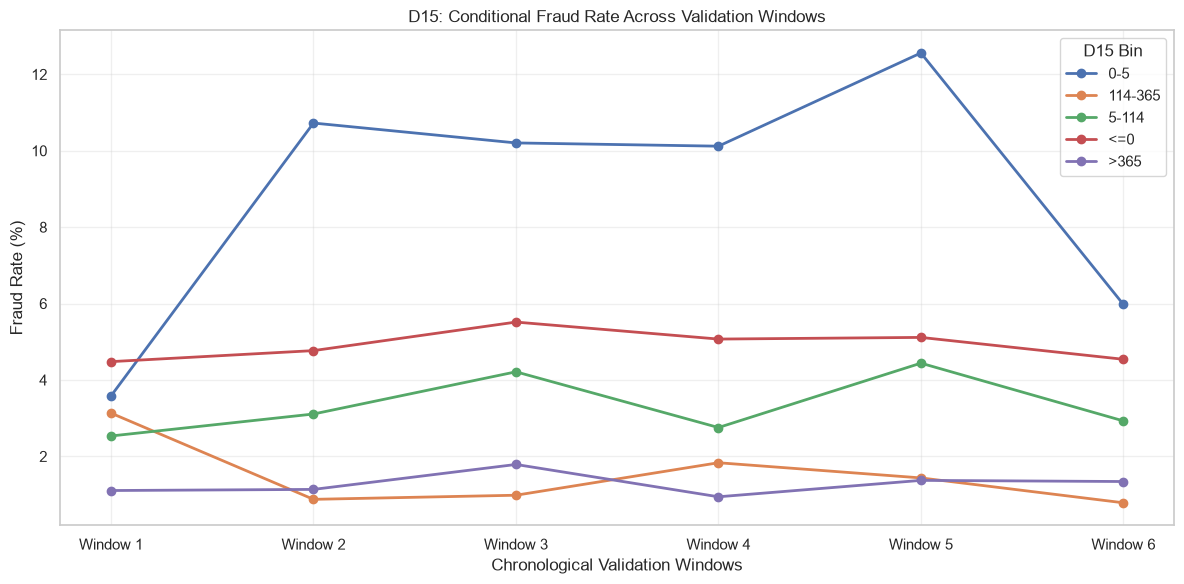

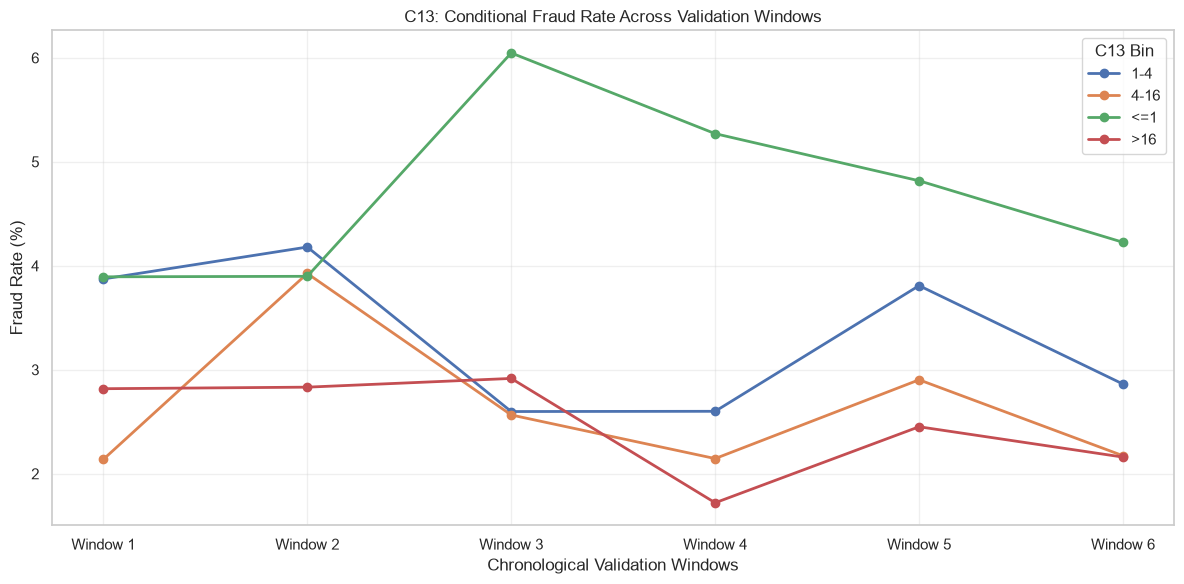

Both conditional fraud-rate charts saved successfully!


In [75]:
# Prepare chart data
d15_plot = d15_fraud_rates.pivot(
    index="Window",
    columns="Bin",
    values="Fraud_Rate"
)

c13_plot = c13_fraud_rates.pivot(
    index="Window",
    columns="Bin",
    values="Fraud_Rate"
)

window_order = [f"Window {i}" for i in range(1, 7)]

d15_plot = d15_plot.reindex(window_order)
c13_plot = c13_plot.reindex(window_order)

# D15 chart
plt.figure(figsize=(12, 6))

for bin_name in d15_plot.columns:
    plt.plot(
        d15_plot.index,
        d15_plot[bin_name] * 100,
        marker="o",
        linewidth=2,
        label=str(bin_name)
    )

plt.title("D15: Conditional Fraud Rate Across Validation Windows")
plt.xlabel("Chronological Validation Windows")
plt.ylabel("Fraud Rate (%)")
plt.legend(title="D15 Bin")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "experiment_plot_D15_conditional_fraud_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# C13 chart
plt.figure(figsize=(12, 6))

for bin_name in c13_plot.columns:
    plt.plot(
        c13_plot.index,
        c13_plot[bin_name] * 100,
        marker="o",
        linewidth=2,
        label=str(bin_name)
    )

plt.title("C13: Conditional Fraud Rate Across Validation Windows")
plt.xlabel("Chronological Validation Windows")
plt.ylabel("Fraud Rate (%)")
plt.legend(title="C13 Bin")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "experiment_plot_C13_conditional_fraud_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both conditional fraud-rate charts saved successfully!")

In [76]:
calibration_variables = [
    "y_eval",
    "proba_eval",
    "platt_proba",
    "isotonic_proba"
]

for variable in calibration_variables:
    print(
        variable,
        "->",
        "Available" if variable in globals() else "Missing"
    )

y_eval -> Available
proba_eval -> Available
platt_proba -> Available
isotonic_proba -> Available


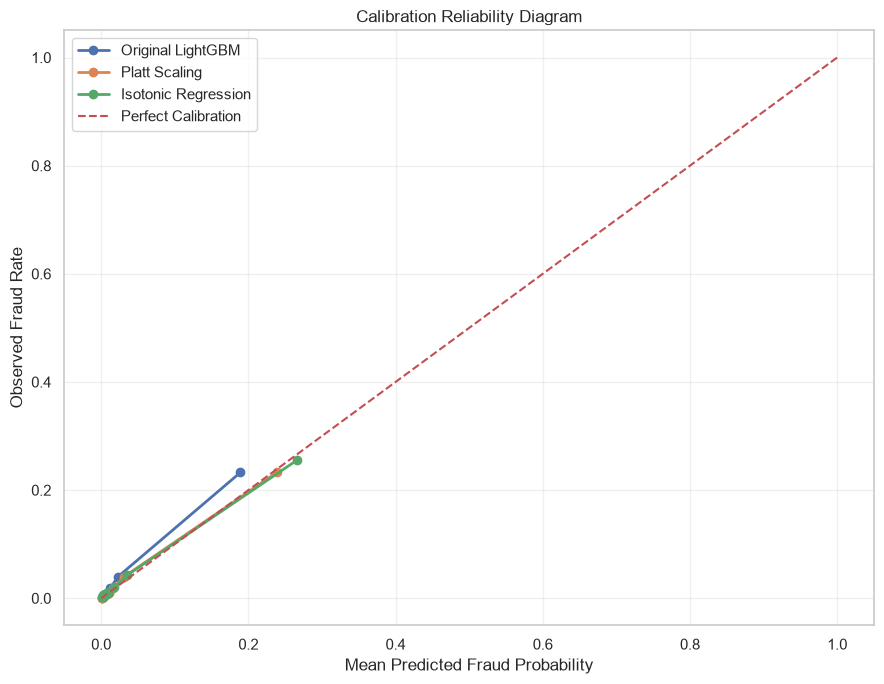

Calibration reliability diagram saved successfully!


In [77]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

# Calculate reliability curves
probabilities = {
    "Original LightGBM": proba_eval,
    "Platt Scaling": platt_proba,
    "Isotonic Regression": isotonic_proba
}

plt.figure(figsize=(9, 7))

for model_name, predictions in probabilities.items():

    observed_rate, mean_predicted = calibration_curve(
        y_eval,
        predictions,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        observed_rate,
        marker="o",
        linewidth=2,
        label=model_name
    )

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.title("Calibration Reliability Diagram")
plt.xlabel("Mean Predicted Fraud Probability")
plt.ylabel("Observed Fraud Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/experiment_plot_calibration_reliability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Calibration reliability diagram saved successfully!")

In [1]:

from pathlib import Path
import os

PROJECT_DIR = Path(r"D:\Fraud-Detection")

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("\nPROJECT DIRECTORY EXISTS:", PROJECT_DIR.exists())

for folder in ["models", "results", "notebooks", "data"]:
    folder_path = PROJECT_DIR / folder

    print(f"\n{'='*50}")
    print(f"{folder.upper()}")

    if folder_path.exists():
        for file in sorted(folder_path.rglob("*")):
            if file.is_file():
                print(file.relative_to(PROJECT_DIR))
    else:
        print("Folder not found")


PROJECT DIRECTORY: D:\Fraud-Detection

PROJECT DIRECTORY EXISTS: True

MODELS
models\isotonic_regression.pkl
models\lightgbm_baseline.pkl
models\platt_scaling.pkl

RESULTS
results\adversarial_feature_importance.csv
results\adversarial_top20_psi.csv
results\all_conditional_fraud_rates.csv
results\bce_isotonic_calibrator.pkl
results\bce_platt_calibrator.pkl
results\calibration_comparison.csv
results\calibration_comparison.png
results\categorical_psi.csv
results\concept_drift_interaction_summary.png
results\concept_drift_interaction_tests.csv
results\conditional_drift_tests.csv
results\conditional_fraud_statistical_tests.csv
results\drift_gap_c13_below_1.png
results\drift_gap_d11_missing.png
results\drift_gap_d15_missing.png
results\drift_gap_id_13_below_41.png
results\drift_gap_id_31_missing.png
results\drift_summary.csv
results\experiment_plot_C13_conditional_fraud_rate.png
results\experiment_plot_calibration_reliability.png
results\experiment_plot_categorical_psi.png
results\experiment